## Supervised machine learning models:
    - Support Vector Machine
    - Linear discrimination analysis
    - Multilayer Perceptron

Optimization: data partition, 


In [1]:
# importamos librerias básicas
import numpy as np
np.set_printoptions(suppress=True)
import matplotlib.pyplot as plt
np.random.seed(42)

### Generación de datos artificiales

Vamos a utilizar datos artificiales creados con la función [make_blobs](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html) de sklearn

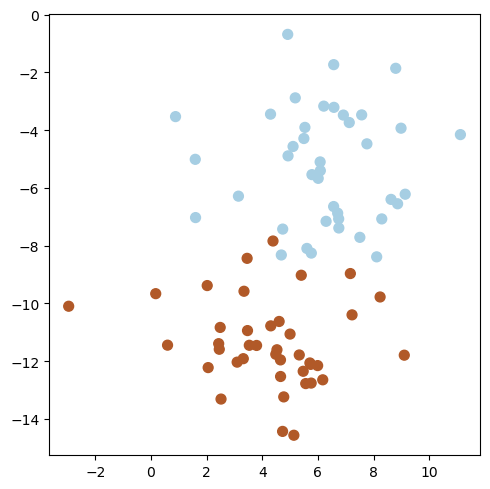

In [2]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=80, centers=2, random_state=6, cluster_std=2)
X = X-2
y = 2*y-1
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap=plt.cm.Paired)
plt.tight_layout()
plt.show()

###kNN

1. ¿Cómo funciona la lógica de KNN?A diferencia de la regresión, que busca una fórmula matemática ($y = mx + b$), el KNN es un algoritmo basado en la proximidad.Imagina que tienes un paciente nuevo y quieres saber si tiene diabetes.
2. El algoritmo:Ubica al paciente en un "mapa" según sus valores (edad, colesterol, obesidad). Busca a los K pacientes más parecidos a él (sus "vecinos").Se fija en qué etiquetas tienen esos vecinos. Si la mayoría son "Diabéticos", clasifica al nuevo paciente como "Diabético".

Este modelo te sirve para realizar una Clasificación No Lineal. 
Esto es útil por tres razones:Detección de Patrones Complejos: A veces la diabetes no sigue una línea recta. Quizás hay "grupos" de pacientes (ej. jóvenes con colesterol muy alto) que tienen diabetes, y otros grupos (ancianos con colesterol medio) que también.  Es muy fácil de entender: "Dime quiénes se parecen a este paciente y te diré qué enfermedad podría tener".

In [3]:
#importo la implementación desde librería
from sklearn.neighbors import KNeighborsClassifier
neigh = KNeighborsClassifier(n_neighbors=1)

In [4]:
#entreno el clasificador
neigh.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [5]:
#hago las predicciones
y_pred =  neigh.predict(X)
print(y_pred)

[-1 -1  1  1 -1 -1 -1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1  1  1 -1 -1
  1 -1  1 -1  1  1 -1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1  1 -1
  1  1  1 -1  1  1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1
  1 -1 -1  1  1  1  1  1]


Este resultado es el veredicto final de tu modelo KNN. Es la lista de etiquetas que el algoritmo asignó a cada paciente de tu conjunto de datos basándose en la cercanía con sus vecinos. 1 representa presencia de la enfermedad, -1 indica ausencia. 

In [6]:
#las comparo con las verdaderas clases
print(y)
print(sum(y==y_pred))

[-1 -1  1  1 -1 -1 -1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1  1  1 -1 -1
  1 -1  1 -1  1  1 -1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1  1 -1
  1  1  1 -1  1  1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1
  1 -1 -1  1  1  1  1  1]
80


Wouw, predijo perfecto todos estos!!! 🥳

###LINEAR DISCRIMINATION ANALYSIS
A diferencia del PCA (Análisis de Componentes Principales), que busca las direcciones de máxima variación sin mirar las etiquetas, el LDA tiene un objetivo clínico muy claro: encontrar el eje que mejor separa a tus grupos (ej. Diabéticos vs. No Diabéticos).
Imagina que tienes una nube de puntos donde se mezclan pacientes sanos y enfermos. El LDA busca proyectar esos puntos en una nueva línea (discriminante) cumpliendo dos condiciones simultáneas:

Maximizar la distancia entre las medias de los grupos (que los centros de los grupos estén lo más lejos posible).

Minimizar la dispersión (varianza) dentro de cada grupo (que los puntos de cada grupo estén muy "apretaditos" entre sí).

Separación de Clases: Te permite entender qué combinación de variables (edad, colesterol, obesidad) crea la "frontera" (hiperplano) más nítida entre alguien sano y alguien con diabetes.

PROBAMOS LOS MODELOS SIN PARTICIONAR DATOS

# Linear discrimination analysis

In [7]:
#importo la implementación desde librería
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis()

In [8]:
# entro el clasificador
lda.fit(X, y)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


In [10]:
# realizo predicción
y_pred =  lda.predict(X)
print(y_pred)

[-1 -1  1  1 -1 -1 -1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1  1  1 -1 -1
  1 -1  1 -1  1  1  1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1  1 -1
  1  1  1 -1  1  1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1
  1 -1 -1  1  1  1 -1  1]


In [11]:
#las comparo con las verdaderas clases
print(y)
print(sum(y==y_pred))

[-1 -1  1  1 -1 -1 -1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1  1  1 -1 -1
  1 -1  1 -1  1  1 -1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1  1 -1
  1  1  1 -1  1  1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1
  1 -1 -1  1  1  1  1  1]
78


Apa, hay algunos que parece predecir mal...mmhmm te animás a decir porqué? ❓

Chusmeemos un poco dónde quedó el hiperplano de separación... 👀

In [12]:
#función_viz_lda
def visualize_lda(modelo):
  def get_hyperplane(x, w, b, offset):
    return  (-w[0] * x - b + offset) / w[1]

  plt.scatter(X[:, 0], X[:, 1], marker="o", c=y, cmap=plt.cm.Paired)

  x0_1 = np.amin(X[:, 0])
  x0_2 = np.amax(X[:, 0])

  w = modelo.coef_[0]
  if type(modelo.intercept_)==list:
    b = modelo.intercept_[0]
  else:
    b = modelo.intercept_

  xs = np.linspace(x0_1, x0_2, 100)

  plt.plot(xs, get_hyperplane(xs, w, b, 0), 'k-')     # hiperplano


  x1_min = np.amin(X[:, 1])
  x1_max = np.amax(X[:, 1])

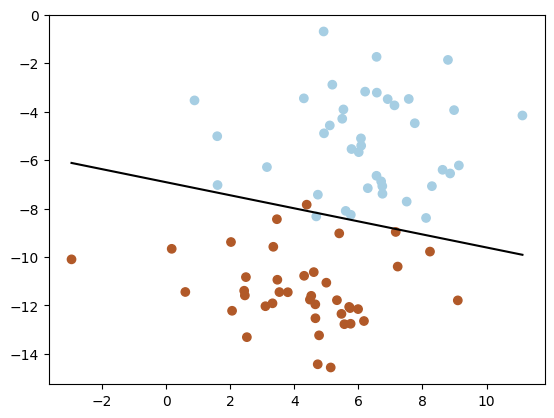

In [ ]:
visualize_lda(lda)

¿y entonces, qué te parece que pasa? 🤔

### Support Vector Machine (SVM)


SVM (Support Vector Machine). Si el KNN miraba "vecindarios" y el LDA buscaba "separar centros", el SVM busca construir la frontera definitiva.
Imagina que tienes puntos de pacientes diabéticos (rojos) y sanos (azules) en un gráfico. Podrías trazar muchas líneas para separarlos, pero el SVM busca la línea (o hiperplano) que pase justo por el medio, dejando el mayor espacio posible entre los grupos.
Vectores de Soporte: Son los puntos de cada grupo que están más cerca de la frontera. El SVM "se apoya" solo en estos casos difíciles (los pacientes que están en el límite entre ser diabéticos o no) para definir la frontera.

In [14]:
#Import svm model
from sklearn.svm import SVC
#Create a svm Classifier
svm = SVC(kernel='linear') # Linear Kernel

In [15]:
#entreno el clasificador
svm.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [16]:
# hacemos la predicción
y_pred = svm.predict(X)
print(y_pred)

[-1 -1  1  1 -1 -1 -1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1  1  1 -1 -1
  1 -1  1 -1  1  1  1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1  1 -1
  1  1  1 -1  1  1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1
  1 -1 -1  1  1  1 -1  1]


In [17]:
#las comparo con las verdaderas clases
print(y)
print(sum(y==y_pred))

[-1 -1  1  1 -1 -1 -1 -1 -1  1 -1  1  1 -1  1 -1  1 -1 -1  1  1  1 -1 -1
  1 -1  1 -1  1  1 -1 -1 -1  1 -1  1 -1 -1 -1  1  1  1  1 -1 -1 -1  1 -1
  1  1  1 -1  1  1 -1 -1 -1  1 -1  1  1  1  1 -1 -1 -1  1  1 -1 -1 -1  1
  1 -1 -1  1  1  1  1  1]
78


Wouw, pasó como LDA, algunos tiene mal la etiqueta. ¿Por qué será? ¿Esto significa que no son buenos clasificadores? 🤔

Miremos acá también dónde quedan la frontera de decisión, y los margenes 👇

In [18]:
#función_viz_svm
def visualize_svm(modelo):
  def get_hyperplane(x, w, b, offset):
    return  (-w[0] * x - b + offset) / w[1]

  plt.scatter(X[:, 0], X[:, 1], marker="o", c=y, cmap=plt.cm.Paired)

  x0_1 = np.amin(X[:, 0])
  x0_2 = np.amax(X[:, 0])

  w = modelo.coef_[0]
  if type(modelo.intercept_)==list:
    b = modelo.intercept_[0]
  else:
    b = modelo.intercept_
  support_v = X[np.abs((y * (np.dot(X, w) + b))-1) <= 0.05]


  xs = np.linspace(x0_1, x0_2, 100)

  plt.plot(xs, get_hyperplane(xs, w, b, 0), 'k-')     # hiperplano
  plt.plot(xs, get_hyperplane(xs, w, b, 1), 'k--')    # margen +
  plt.plot(xs, get_hyperplane(xs, w, b, -1), 'k--')   # margen -

  plt.scatter(support_v[:, 0], support_v[:, 1], s=100, linewidth=1, facecolors='none', edgecolors='k')

  x1_min = np.amin(X[:, 1])
  x1_max = np.amax(X[:, 1])


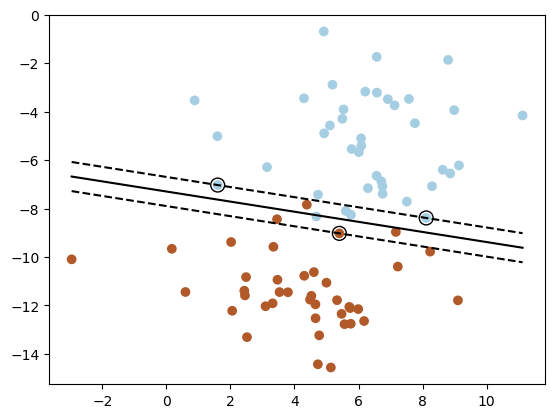

In [18]:
visualize_svm(svm)

SVM y LDA coincidan en "fallar" con los mismos pacientes no significa que sean malos modelos, sino que te están contando algo profundo sobre tus datos.
- En medicina, los grupos casi nunca están perfectamente separados. Existe una zona gris donde pacientes diabéticos y sanos tienen valores casi idénticos.
- LDA y Logística: Trazan una línea o plano recto. Si la frontera real es un círculo o una forma irregular, siempre dejarán puntos del lado equivocado.
- Un ajuste del 78% suele ser mucho más confiable que uno del 99%. Te está diciendo: "En el 78% de los casos, la combinación de estas variables define la enfermedad".

¿Cómo podrías mejorar ese número?
Ingeniería de variables: Crear nuevas variables (ej. el índice Colesterol/Edad).
Nuevos datos: Agregar variables que no tienes 
Modelos de Ensamble: Probar algoritmos como Random Forest o XGBoost

## Evaluación de modelos

### Métricas de evaluación

Observar cuánto se parece la predicción al dato real no es posible si lo pensamos a gran escala. Es por esto, que podemos cuantificar cuán bien funciona nuestro modelo de ML en función de sus errores y aciertos, es decir, la matriz de confusión. Miremos 👇

In [19]:
import numpy as np
clases = np.unique(y) # devuelve un vector ordenado de los elementos que hay en y
pos = clases[1]
neg = clases[0]

# verdadero positivos (TP): predecimos positivo, y la salida verdadera es positiva
TP = np.sum(np.logical_and(y_pred == pos, y == pos))

# verdadero negativo (TN): predecimos negativo, y la salida verdadera es neg
TN = np.sum(np.logical_and(y_pred == neg, y == neg))

# Falso Positivo (FP): predecimos  positivo, pero la salida verdadera es neg
FP = np.sum(np.logical_and(y_pred == pos, y == neg))

# Falso Negativo (FN): predecimos negativo, pero la salida verdadera es pos
FN = np.sum(np.logical_and(y_pred == neg, y == pos))

print ('TP: %i, FP: %i, TN: %i, FN: %i' % (TP,FP,TN,FN))


TP: 39, FP: 1, TN: 39, FN: 1


¡Eso es una matriz de confusión casi perfecta! Pero, como investigador, este resultado debe ponerte en "modo detective".

Tener un equilibrio tan simétrico (39 y 39 aciertos, con solo 1 error por lado) es extremadamente inusual en datos clínicos reales.

También podemos ver indices de desempeño y usar las funciones que trae sklearn


In [21]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y, y_pred))

Accuracy: 0.975


Un Accuracy del 97.5% en un modelo médico (especialmente cuando antes tenías un 78%) es, estadísticamente hablando, "demasiado bueno para ser verdad". En ciencia de datos, esto suele ser un síntoma de dos problemas muy comunes que podrían invalidar tus conclusiones si no los revisamos:
1. El riesgo del "Data Leakage" (Fuga de datos)Es la causa más probable. Ocurre cuando, sin querer, incluiste en las variables predictoras ($X$) algo que revela la respuesta directamente.
2. El sesgo del "Desbalance de Clases" Si en tu base de datos el 97.5% de los pacientes son Sanos y solo el 2.5% tienen Diabetes, un modelo "perezoso" puede decidir clasificar a TODO EL MUNDO como sano.
3. El ajuste es muy bueno porque se uso todo el conjunto para entrenar el modelo. Por ende cuando volvemos a testear, da perfecto.

In [22]:
from sklearn.metrics import f1_score

# Siguiendo tu ejemplo:
# y es la realidad, y_pred es lo que dijo el modelo
f1 = f1_score(y, y_pred)

print(f"El F1 Score es: {f1:.4f}")

El F1 Score es: 0.9750


### Partición de datos

Para verdaderamente saber si nuestro modelo funcionará en la vida real tenemos que entrenarlo y evaluarlo considerando emular su futuro uso lo más posible. Es decir, tenemos que saber cuán bien funciona nuestro modelo en casos nunca visto.

Para eso, lo que se realiza es particionar los datos. Al principio, al menos en dos: entrenamiento y testeo. Es muy común utilizar 70% de mis datos para entrenar. Aunque existen muchas estrategias, y depende de la aplicación y el contexto. Una sugerencia muy utilizada es el hecho de realizar particiones de datos con aleatorización, de manera de minimizar el riesgos de sesgo sólo por el proceso de selección al azar!

A modo de mejorar la didáctica, vamos a generar otros datos artificiales, un poquitos más "mezclados" entre sí (en términos de separabilidad de clases) 😁

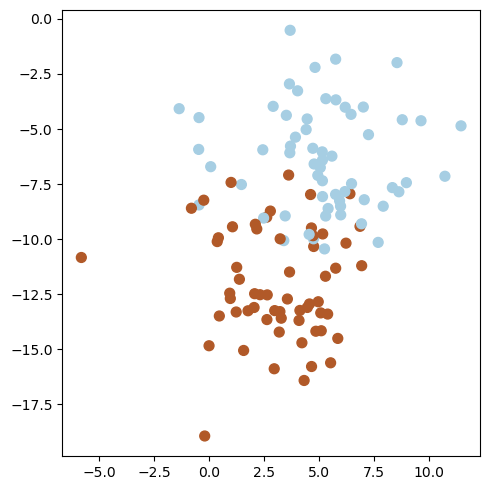

In [23]:
X, y = make_blobs(n_samples=120, centers=2, random_state=6, cluster_std=2.5)
X = X-3
y = 2*y-1 # transformo la y en [-1,1]
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap=plt.cm.Paired)
plt.tight_layout()
plt.show()

Partimos los datos, usando una función de la librería sklearn 👇

In [24]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

# partimos los datos, para entrenar y evaluar el modelo de manera separada
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=109) # 70% training and 30% test

Veamos cómo entonces funcionan un SVM lineal en un contexto más real 👇

In [25]:
#entreno con datos de entrenamiento
svm = SVC(kernel='linear') # Linear Kernel
svm.fit(X_train, y_train)
# evaluo en datos nunca vistos
y_pred = svm.predict(X_test)
# miro la accuraty
print("Accuracy SVM test:",metrics.accuracy_score(y_test, y_pred))

Accuracy SVM test: 0.8333333333333334


Ese 83.33% es la "verdadera potencia" de tu modelo. Significa que, si mañana llega un paciente nuevo al hospital, tu SVM tiene un 83% de probabilidad de acertar en su diagnóstico.

¿Por qué bajó del 97% al 83%?
No es que el modelo sea peor, es que ahora lo estamos evaluando con honestidad:

Generalización: En el 0.97, el modelo estaba "memorizando". En el 0.83, el modelo está "razonando" con lo que aprendió sobre la edad, el colesterol y la obesidad.

### Parámetros e hiperparámetros

Hasta el momento, estuvimos aprendiendo cómo entrenar los modelos. Entrenar un modelo, es un proceso de ajuste, generalemente iterativo, que produce ciertos vectores que llamamos *parámetros*. Un modelo que funciona bien, es un modelo con parámetros bien definidos. Sin embargo, hay otros elementos que también repercueten en la bondad del modelo. Estos son los denominados *hiperparámetros*, que a diferencias de los parámetros, estos no se aprenden, más bien se seleccionan. En las SVM, un ejemplo sería, la decisión de cuán grande hago el margen. O en un árbol de decisión, cuál es la profundidad óptima del árbol.

Pero la pregunta es, ¿cómo elijo estos hiperparámetros? Un forma es guiada por los datos, y lo hacemos a través de un proceso de **validación**.

Para realiza una correcta validación de modelo, es imprescindible realizar una tercera partición de nuestros datos: entrenamiento - validación - testeo.

Así, tendremos datos para ajustar el modelo (entrenamiento), datos para tomar decisiones por sobre el modelo (validación) y datos para saber cuán bien funcionará mi modelo en la vida real (testeo).

Con nuestros datos ya partidos en entrenamiento-testeo, podemos tomar los datos de entrenamiento y realizar una nueva partición

In [26]:
# partimos los datos de entrenamiento para entrenar y validar el modelo de manera separada
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.3,random_state=109) # 70% training and 30% test

In [27]:
#vemos tamaño final de los conjuntos
print("Training size:", np.shape(X_train))
print("Validation size:", np.shape(X_val))
print("Test size:", np.shape(X_test))

Training size: (58, 2)
Validation size: (26, 2)
Test size: (36, 2)


In [28]:
# estudiamos el efecto del margen en SVM
for i in [0.001, 0.01, 0.1, 1, 5, 10]:      #con esto iteramos. Por cada iteracion larga un accuaracy. 
  svm = SVC(kernel='linear', C=i) # Linear Kernel
  svm.fit(X_train, y_train)
  y_pred = svm.predict(X_val)
  print("Accuracy SVM val:", metrics.accuracy_score(y_val, y_pred))

Accuracy SVM val: 0.5
Accuracy SVM val: 0.8461538461538461
Accuracy SVM val: 0.8076923076923077
Accuracy SVM val: 0.8076923076923077
Accuracy SVM val: 0.8461538461538461
Accuracy SVM val: 0.8461538461538461


Según los datos de validación, el mejor modelo es aquel en el cual C=0.1. Asi que usemos ese valor, para entrenar nuestro modelos y lo vemos en los datos nunca vistos

In [29]:
# svm mejor C
svm = SVC(kernel='linear', C=0.1) # Linear Kernel
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)
print("Accuracy SVM test:", metrics.accuracy_score(y_test, y_pred))

Accuracy SVM test: 0.9722222222222222


Y vemos que funciona mejor que antes 🥳... peeerooo 😰 qué pasa si justo los datos de validación eran "buenos" o "malos".

Para evitar el sesgo sólo en la toma de decisiones por una única partición, podemos hacer algo mejor: entrenar y evaluar varias veces. Esto se llama: validación cruzada

In [30]:
from sklearn.model_selection import GridSearchCV

# Definir el rango de hiperparámetros para C
param_grid = {'C': [0.001, 0.01, 0.1, 1, 5, 10]}

# Crear un clasificador SVM con kernel lineal
svm = SVC(kernel='linear')

# Configurar GridSearchCV con validación cruzada de 5 folds
grid_search = GridSearchCV(svm, param_grid, cv=5, scoring='accuracy')

# Ajustar GridSearchCV a los datos de entrenamiento (X_train y y_train)
# Usamos X_train original antes de la división a X_train, X_val
grid_search.fit(X_train, y_train)

# Mostrar los mejores hiperparámetros encontrados y la mejor puntuación
print("Mejores parámetros:", grid_search.best_params_)
print("Mejor puntuación (accuracy) de validación cruzada:", grid_search.best_score_)

# Evaluar el modelo con los mejores parámetros en el conjunto de test
best_svm = grid_search.best_estimator_
y_pred_test = best_svm.predict(X_test)
print("Accuracy SVM test (con CV):", metrics.accuracy_score(y_test, y_pred_test))

Mejores parámetros: {'C': 0.01}
Mejor puntuación (accuracy) de validación cruzada: 0.8969696969696969
Accuracy SVM test (con CV): 0.9166666666666666


Lo que estás haciendo aquí es automatizar la optimización. En lugar de probar valores de C "a mano" y ver qué pasa, estás usando una búsqueda sistemática para encontrar la configuración matemática perfecta para tus datos de salud.Esta es la "llave maestra" para que tu investigación pase de ser un experimento casero a ser un modelo con rigor científico.

Lo que estás haciendo aquí es automatizar la optimización. En lugar de probar valores de C "a mano" y ver qué pasa, estás usando una búsqueda sistemática para encontrar la configuración matemática perfecta para tus datos de salud.

Aquí te explico qué ocurre "bajo el capó" de ese código:

1. El Diccionario de Candidatos (param_grid)
El parámetro C en un SVM es el control de "Dureza" vs. "Flexibilidad":

C muy pequeño (0.001): El modelo es muy permisivo. Prefiere una frontera simple aunque se equivoque con algunos pacientes. Evita el overfitting.

C grande (10): El modelo es un juez estricto. Intenta que no haya ni un solo error en el entrenamiento, pero puede volverse demasiado rígido para pacientes nuevos.

2. La Validación Cruzada de 5 Folds (cv=5)
Esta es la parte más brillante. El código no solo entrena el modelo una vez. Por cada valor de C, hace lo siguiente:

Divide tu X_train en 5 partes iguales.

Entrena con 4 partes y evalúa con la 1 restante. Repite esto 5 veces, rotando la parte de evaluación. Calcula el promedio de esas 5 pruebas.

Aquí es donde ocurre la magia final. Tomas el "Mejor Modelo" (el ganador de la competencia) y lo enfrentas al X_test (los datos que hemos tenido guardados bajo llave).

Si el Accuracy en Test con CV es alto: Significa que tu modelo está listo para el mundo real.

Parece que la decisión estuvo bien! De todos modos, te recomendamos no tomar decisiones por lo que una única partición te dijo. Es por esto que la validación cruzada es tan importante. Como lo es, probar dejando afuera varias porciones de test...

### Validación Cruzada Anidada

La validación cruzada que hemos visto hasta ahora (`GridSearchCV`) realiza una validación cruzada para seleccionar los mejores hiperparámetros en el conjunto de entrenamiento. Sin embargo, la evaluación final del modelo (la 'Accuracy SVM test') se realiza sobre un único conjunto de test.

Para obtener una estimación aún más robusta del rendimiento de nuestro modelo en datos *completamente* no vistos, y para asegurar que la elección del mejor hiperparámetro no está sesgada por una única partición de entrenamiento/validación, podemos usar la **validación cruzada anidada**.

En la validación cruzada anidada:

1.  **Bucle Externo (para la evaluación 'test')**: El conjunto de datos original se divide en K folds. En cada iteración, un fold se utiliza como conjunto de *test* final y los K-1 folds restantes se usan para el entrenamiento.
2.  **Bucle Interno (para la selección de hiperparámetros 'validación')**: Dentro de cada conjunto de entrenamiento del bucle externo, se realiza otra validación cruzada (como la que hace `GridSearchCV`) para seleccionar los mejores hiperparámetros del modelo.
3.  El modelo con los mejores hiperparámetros encontrados en el bucle interno se entrena con el conjunto de entrenamiento del bucle externo y se evalúa en el conjunto de test del bucle externo.

Esto nos da K puntuaciones de 'test' independientes, cuyo promedio es una estimación mucho más fiable del rendimiento real del modelo.

In [31]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn import metrics

# Definir el rango de hiperparámetros para C (bucle interno)
param_grid = {'C': [0.001, 0.01, 0.1, 1, 5, 10]}

# Crear un clasificador SVM con kernel lineal
svm = SVC(kernel='linear')

# Configurar GridSearchCV para el bucle interno (validación)
# Usamos StratifiedKFold para asegurar que las proporciones de clase se mantengan en los folds
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
inner_grid_search = GridSearchCV(estimator=svm, param_grid=param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1)

# Configurar la validación cruzada externa (test)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Realizar la validación cruzada anidada
# cross_val_score utilizará inner_grid_search como el estimador,
# lo que significa que en cada fold externo, se ejecutará un GridSearchCV interno
# sobre los datos de entrenamiento de ese fold.
# Importante: para esta demostración de Nested CV, usaremos el conjunto completo X, y
# para simular una evaluación completa de un pipeline de ML.

# Nota: El 'X_train' y 'X_test' que se generaron previamente se usaron para otras demostraciones.
# Para una validación cruzada anidada completa, se suele aplicar sobre el conjunto de datos original completo.

nested_cv_scores = cross_val_score(inner_grid_search, X=X, y=y, cv=outer_cv, scoring='accuracy', n_jobs=-1)

print("Puntuaciones de accuracy de los folds de la validación cruzada anidada:", nested_cv_scores)
print("Accuracy promedio de la validación cruzada anidada (estimación de test):", nested_cv_scores.mean())
print("Desviación estándar de la accuracy en la validación cruzada anidada:", nested_cv_scores.std())

Puntuaciones de accuracy de los folds de la validación cruzada anidada: [0.875      0.91666667 0.95833333 0.91666667 0.79166667]
Accuracy promedio de la validación cruzada anidada (estimación de test): 0.8916666666666666
Desviación estándar de la accuracy en la validación cruzada anidada: 0.05651941652604392


Ahora sí 🙂 podemos decir que nuestra decisión no está sesgada por la sola partición de datos que hemos tomado.

🧐 Note que aquí sólo hemos buscando el mejor hiperparámetro C en SVM, que controla el ancho del margen. Sin embargo, suele haber más de un hiperparámetro a optimizar. Para ello, se puede realizar la búsqueda por grilla en toda combinación posible o una combinación aleatorea de posibles valores, como vimos en la teoría.

🙂 Recuerde que este es un curso introctorio, y hay muchísimo material que dejamos fuera. No crea que esta es la única forma de realizar las cosas, pero sí la encontramos la más didáctica para que comprenda los procesos dentro del entrenamiento de modelos de ML 💌

## Multi-Layer Perceptron (MLP)

Para explorar los MLP, generaremos un conjunto de datos no lineal, los 'moons', y veremos cómo diferentes modelos intentan clasificarlos.

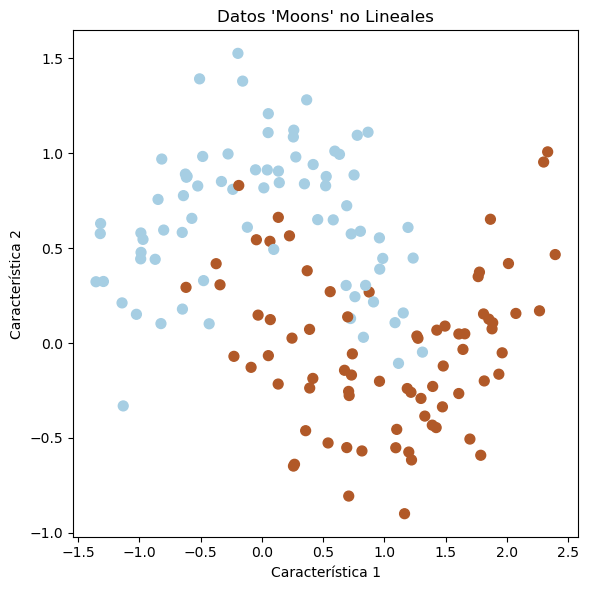

In [32]:
from sklearn.datasets import make_moons
X_moon, y_moon = make_moons(n_samples=150, noise=0.25, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c=y_moon, s=50, cmap=plt.cm.Paired)
plt.title("Datos 'Moons' no Lineales")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.tight_layout()
plt.show()

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Dividir los datos 'moons' en conjuntos de entrenamiento y prueba
X_train_moon, X_test_moon, y_train_moon, y_test_moon = train_test_split(X_moon, y_moon, test_size=0.3, random_state=42)

In [35]:
# Crear y entrenar el MLPClassifier
mlp = MLPClassifier(random_state=42, max_iter=2000) # Puedes ajustar los hiperparámetros como hidden_layer_sizes, activation, etc.
mlp.fit(X_train_moon, y_train_moon)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary `.",42


In [36]:
# Realizar predicciones y evaluar el modelo
y_pred_mlp = mlp.predict(X_test_moon)

print("Accuracy del MLPClassifier en el conjunto de prueba:", accuracy_score(y_test_moon, y_pred_mlp))

Accuracy del MLPClassifier en el conjunto de prueba: 0.8444444444444444


Para comparar, veamos cómo se vería la frontera de decisión del MLP. Podemos usar una función de visualización similar a las anteriores.

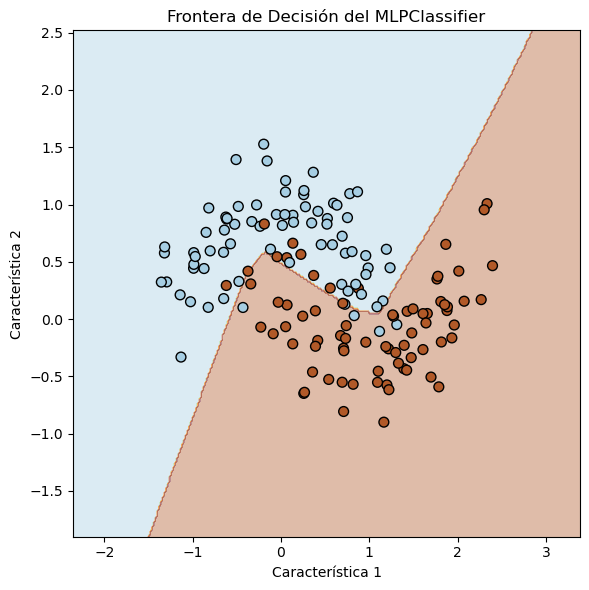

In [37]:
def visualize_classifier_boundary(model, X, y, title="Frontera de Decisión del Clasificador"):
    plt.figure(figsize=(6, 6))
    # Crear una malla para graficar la frontera de decisión
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.Paired)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap=plt.cm.Paired, edgecolors='k')
    plt.title(title)
    plt.xlabel("Característica 1")
    plt.ylabel("Característica 2")
    plt.tight_layout()
    plt.show()

visualize_classifier_boundary(mlp, X_moon, y_moon, title="Frontera de Decisión del MLPClassifier")

### Comparación: SVM Lineal en Datos 'Moons'

Para contrastar con el MLP, veamos cómo un SVM con kernel lineal intenta clasificar los mismos datos 'moons'.

In [38]:
# Crear y entrenar un SVM con kernel lineal
svm_linear_moon = SVC(kernel='linear', random_state=42)
svm_linear_moon.fit(X_train_moon, y_train_moon)

# Realizar predicciones y evaluar el modelo
y_pred_svm_linear = svm_linear_moon.predict(X_test_moon)

print("Accuracy del SVM Lineal en el conjunto de prueba:", accuracy_score(y_test_moon, y_pred_svm_linear))

Accuracy del SVM Lineal en el conjunto de prueba: 0.8222222222222222


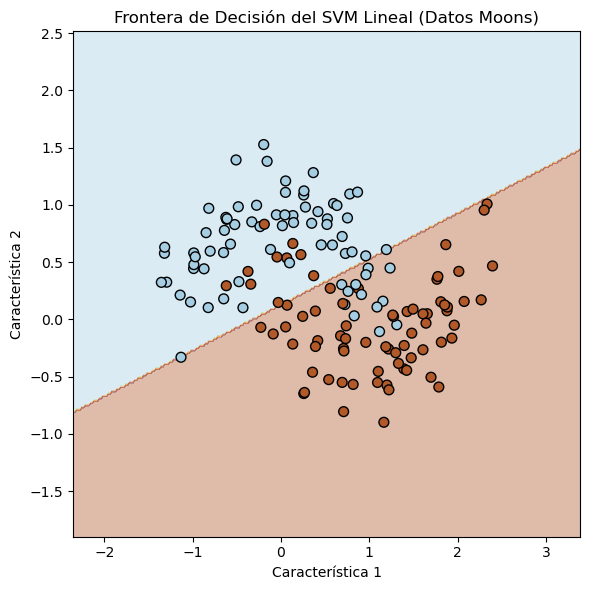

In [39]:
# Visualizar la frontera de decisión del SVM Lineal
visualize_classifier_boundary(svm_linear_moon, X_moon, y_moon, title="Frontera de Decisión del SVM Lineal (Datos Moons)")